In [1]:
# Assignment 7: Pedestrian Detection using OpenCV

import os
import re
import glob

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

In [2]:
hog = cv2.HOGDescriptor()

hog.setSVMDetector(
    cv2.HOGDescriptor_getDefaultPeopleDetector()
)

print("HOG descriptor created with the default people detector.")
print("Window size :", hog.winSize)
print("Block size  :", hog.blockSize)
print("Cell size   :", hog.cellSize)

HOG descriptor created with the default people detector.
Window size : (64, 128)
Block size  : (16, 16)
Cell size   : (8, 8)


In [3]:
dataset_path = r"C:\Users\JINESHA GANDHI\Downloads\tata-techpulse-ai-ml\Assignment-7-Pedestrian-Detection-OpenCV\PennFudanPed"

image_files = sorted(
    glob.glob(os.path.join(dataset_path, "PNGImages", "*.png"))
)

print("Images found:", len(image_files))

Images found: 170


In [4]:
box_pattern = re.compile(
    r"\(Xmin, Ymin\) - \(Xmax, Ymax\) : \((\d+), (\d+)\) - \((\d+), (\d+)\)"
)


def read_ground_truth(image_file):
    name = os.path.basename(image_file).replace(".png", ".txt")
    annotation_file = os.path.join(dataset_path, "Annotation", name)

    with open(annotation_file) as f:
        text = f.read()

    return [
        tuple(int(value) for value in match)
        for match in box_pattern.findall(text)
    ]


ground_truth = {
    image_file: read_ground_truth(image_file)
    for image_file in image_files
}

total_pedestrians = sum(len(boxes) for boxes in ground_truth.values())

print("Total annotated pedestrians:", total_pedestrians)
print("Average per image:", round(total_pedestrians / len(image_files), 2))

Total annotated pedestrians: 423
Average per image: 2.49


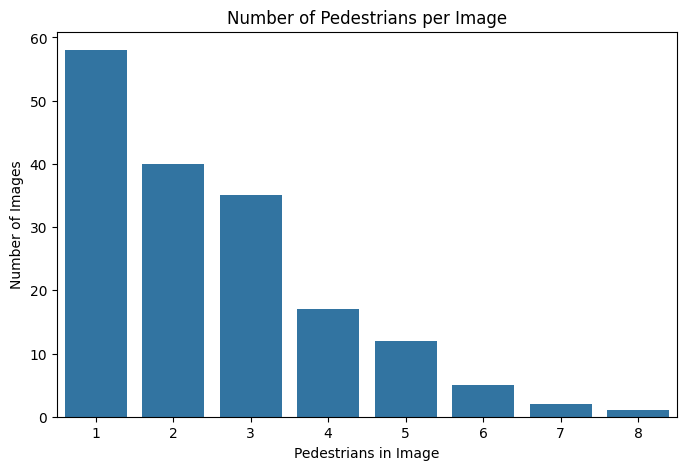

count    170.000000
mean       2.488235
std        1.527802
min        1.000000
25%        1.000000
50%        2.000000
75%        3.000000
max        8.000000
dtype: float64


In [5]:
counts = pd.Series([len(b) for b in ground_truth.values()])

plt.figure(figsize=(8, 5))

sns.countplot(x=counts)

plt.title("Number of Pedestrians per Image")
plt.xlabel("Pedestrians in Image")
plt.ylabel("Number of Images")
plt.show()

print(counts.describe())

In [6]:
# The default people detector returns boxes with extra space around the
# person, so they are tightened before comparing with the ground truth
def detect_pedestrians(image, win_stride=(8, 8), scale=1.05, adjust=True):
    boxes, weights = hog.detectMultiScale(
        image,
        winStride=win_stride,
        padding=(8, 8),
        scale=scale
    )

    results = []

    for (x, y, w, h) in boxes:
        if adjust:
            x = x + int(0.15 * w)
            y = y + int(0.07 * h)
            w = int(0.70 * w)
            h = int(0.83 * h)

        results.append((x, y, x + w, y + h))

    return results

In [7]:
sample_file = image_files[0]

sample_image = cv2.imread(sample_file)

detections = detect_pedestrians(sample_image)

print("File:", os.path.basename(sample_file))
print("Ground truth pedestrians:", len(ground_truth[sample_file]))
print("Detected pedestrians    :", len(detections))

File: FudanPed00001.png
Ground truth pedestrians: 2
Detected pedestrians    : 2


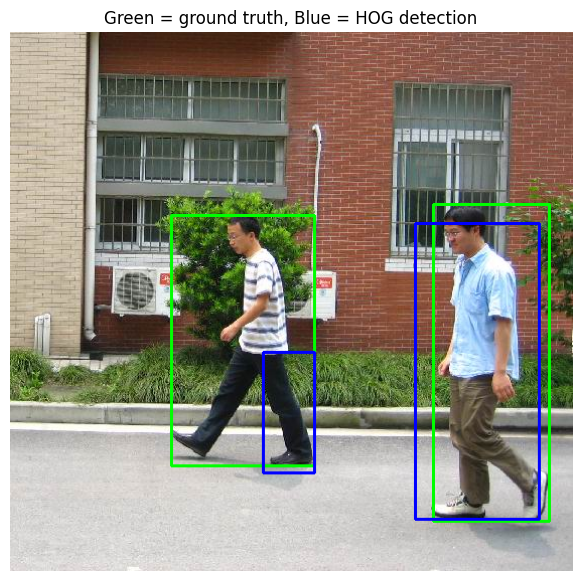

In [8]:
def draw_boxes(image, truth_boxes, detected_boxes):
    output = image.copy()

    for (x1, y1, x2, y2) in truth_boxes:
        cv2.rectangle(output, (x1, y1), (x2, y2), (0, 255, 0), 2)

    for (x1, y1, x2, y2) in detected_boxes:
        cv2.rectangle(output, (x1, y1), (x2, y2), (255, 0, 0), 2)

    return cv2.cvtColor(output, cv2.COLOR_BGR2RGB)


plt.figure(figsize=(8, 7))

plt.imshow(
    draw_boxes(sample_image, ground_truth[sample_file], detections)
)

plt.title("Green = ground truth, Blue = HOG detection")
plt.axis("off")
plt.show()

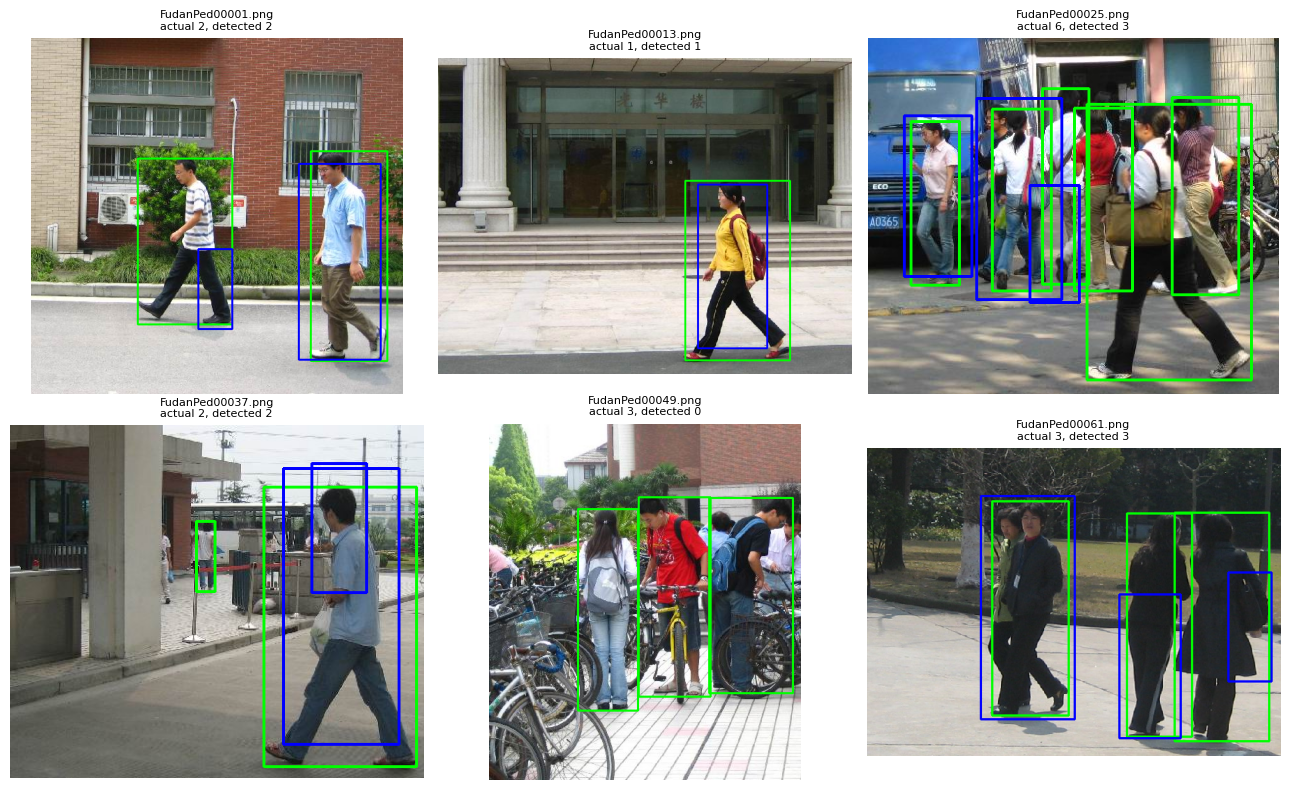

In [9]:
plt.figure(figsize=(13, 8))

for i in range(6):
    image_file = image_files[i * 12]
    image = cv2.imread(image_file)

    detected = detect_pedestrians(image)

    plt.subplot(2, 3, i + 1)
    plt.imshow(draw_boxes(image, ground_truth[image_file], detected))
    plt.title(
        "%s\nactual %d, detected %d" % (
            os.path.basename(image_file),
            len(ground_truth[image_file]),
            len(detected)
        ),
        fontsize=8
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

In [10]:
def calculate_iou(box_a, box_b):
    x1 = max(box_a[0], box_b[0])
    y1 = max(box_a[1], box_b[1])
    x2 = min(box_a[2], box_b[2])
    y2 = min(box_a[3], box_b[3])

    overlap = max(0, x2 - x1) * max(0, y2 - y1)

    area_a = (box_a[2] - box_a[0]) * (box_a[3] - box_a[1])
    area_b = (box_b[2] - box_b[0]) * (box_b[3] - box_b[1])

    union = area_a + area_b - overlap

    if union == 0:
        return 0

    return overlap / union


print("IoU of a box with itself:", calculate_iou((0, 0, 10, 10), (0, 0, 10, 10)))
print("IoU of two separate boxes:", calculate_iou((0, 0, 10, 10), (50, 50, 60, 60)))

IoU of a box with itself: 1.0
IoU of two separate boxes: 0.0


In [11]:
# A detection counts as correct when it overlaps a real pedestrian
# by at least half of their combined area
IOU_THRESHOLD = 0.5


def score_image(truth_boxes, detected_boxes):
    matched = set()
    true_positives = 0

    for detected in detected_boxes:
        best_iou = 0
        best_index = -1

        for index, truth in enumerate(truth_boxes):
            if index in matched:
                continue

            iou = calculate_iou(detected, truth)

            if iou > best_iou:
                best_iou = iou
                best_index = index

        if best_iou >= IOU_THRESHOLD:
            matched.add(best_index)
            true_positives += 1

    false_positives = len(detected_boxes) - true_positives
    false_negatives = len(truth_boxes) - true_positives

    return true_positives, false_positives, false_negatives

In [12]:
def evaluate(win_stride, scale, adjust=True):
    total_tp = 0
    total_fp = 0
    total_fn = 0

    for image_file in image_files:
        image = cv2.imread(image_file)

        detected = detect_pedestrians(image, win_stride, scale, adjust)

        tp, fp, fn = score_image(ground_truth[image_file], detected)

        total_tp += tp
        total_fp += fp
        total_fn += fn

    precision = total_tp / (total_tp + total_fp) if total_tp + total_fp else 0
    recall = total_tp / (total_tp + total_fn) if total_tp + total_fn else 0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0

    return {
        "Window Stride": str(win_stride),
        "Scale": scale,
        "True Positives": total_tp,
        "False Positives": total_fp,
        "False Negatives": total_fn,
        "Precision": round(precision, 3),
        "Recall": round(recall, 3),
        "F1": round(f1, 3)
    }


print("Evaluation function ready.")

Evaluation function ready.


In [13]:
raw_result = evaluate((4, 4), 1.05, adjust=False)
adjusted_result = evaluate((4, 4), 1.05, adjust=True)

box_comparison = pd.DataFrame([
    dict(raw_result, Boxes="Raw detector output"),
    dict(adjusted_result, Boxes="Tightened boxes")
])

box_comparison[[
    "Boxes",
    "True Positives",
    "False Positives",
    "False Negatives",
    "Precision",
    "Recall",
    "F1"
]]

,Boxes,True Positives,False Positives,False Negatives,Precision,Recall,F1
0,Raw detector output,175,356,248,0.33,0.414,0.367
1,Tightened boxes,255,276,168,0.48,0.603,0.535


In [14]:
settings = [
    ((8, 8), 1.05),
    ((8, 8), 1.10),
    ((4, 4), 1.05)
]

results = []

for win_stride, scale in settings:
    result = evaluate(win_stride, scale)
    results.append(result)
    print(result)

{'Window Stride': '(8, 8)', 'Scale': 1.05, 'True Positives': 213, 'False Positives': 153, 'False Negatives': 210, 'Precision': 0.582, 'Recall': 0.504, 'F1': 0.54}


{'Window Stride': '(8, 8)', 'Scale': 1.1, 'True Positives': 179, 'False Positives': 103, 'False Negatives': 244, 'Precision': 0.635, 'Recall': 0.423, 'F1': 0.508}


{'Window Stride': '(4, 4)', 'Scale': 1.05, 'True Positives': 255, 'False Positives': 276, 'False Negatives': 168, 'Precision': 0.48, 'Recall': 0.603, 'F1': 0.535}


In [15]:
results_df = pd.DataFrame(results)

results_df

,Window Stride,Scale,True Positives,False Positives,False Negatives,Precision,Recall,F1
0,"(8, 8)",1.05,213,153,210,0.582,0.504,0.540
1,"(8, 8)",1.10,179,103,244,0.635,0.423,0.508
2,"(4, 4)",1.05,255,276,168,0.480,0.603,0.535


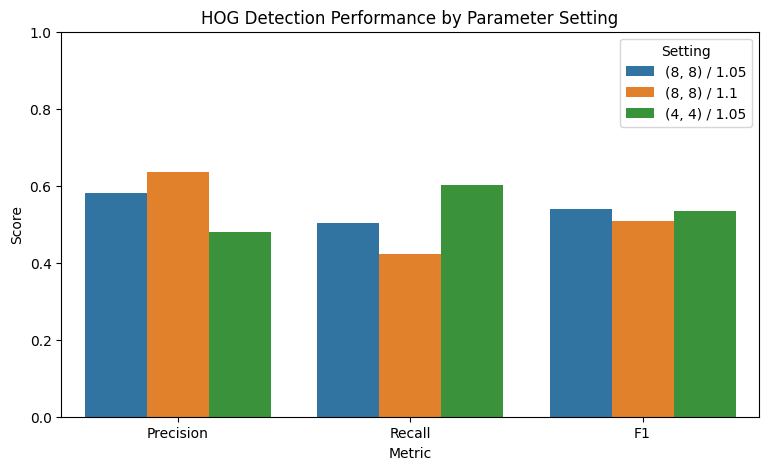

In [16]:
comparison = results_df.melt(
    id_vars=["Window Stride", "Scale"],
    value_vars=["Precision", "Recall", "F1"],
    var_name="Metric",
    value_name="Score"
)

comparison["Setting"] = (
    comparison["Window Stride"] + " / " + comparison["Scale"].astype(str)
)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=comparison,
    x="Metric",
    y="Score",
    hue="Setting"
)

plt.title("HOG Detection Performance by Parameter Setting")
plt.ylim(0, 1)
plt.show()

In [17]:
best_stride, best_scale = settings[
    int(results_df["F1"].idxmax())
]

per_image = []

for image_file in image_files:
    image = cv2.imread(image_file)

    detected = detect_pedestrians(image, best_stride, best_scale)

    tp, fp, fn = score_image(ground_truth[image_file], detected)

    per_image.append({
        "File": os.path.basename(image_file),
        "Actual": len(ground_truth[image_file]),
        "Detected": len(detected),
        "Correct": tp,
        "Missed": fn,
        "False Alarms": fp
    })

per_image_df = pd.DataFrame(per_image)

print("Images where every pedestrian was found:",
      int((per_image_df["Missed"] == 0).sum()))
print("Images where nothing was detected:",
      int((per_image_df["Detected"] == 0).sum()))

per_image_df.head(10)

Images where every pedestrian was found: 55
Images where nothing was detected: 25


,File,Actual,Detected,Correct,Missed,False Alarms
0,FudanPed00001.png,2,2,1,1,1
1,FudanPed00002.png,1,1,0,1,1
2,FudanPed00003.png,1,1,1,0,0
3,FudanPed00004.png,2,2,2,0,0
4,FudanPed00005.png,2,0,0,2,0
5,FudanPed00006.png,2,1,1,1,0
6,FudanPed00007.png,3,4,2,1,2
7,FudanPed00008.png,2,2,1,1,1
8,FudanPed00009.png,2,0,0,2,0
9,FudanPed00010.png,1,1,1,0,0


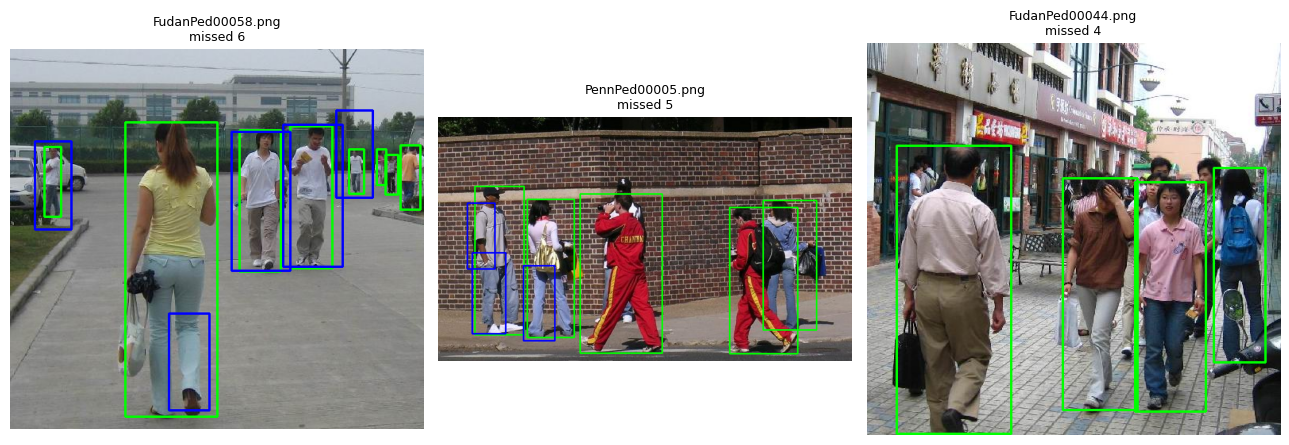

In [18]:
difficult = per_image_df.sort_values(
    by="Missed",
    ascending=False
).head(3)

plt.figure(figsize=(13, 5))

for i, file_name in enumerate(difficult["File"].values):
    image_file = os.path.join(dataset_path, "PNGImages", file_name)
    image = cv2.imread(image_file)

    detected = detect_pedestrians(image, best_stride, best_scale)

    plt.subplot(1, 3, i + 1)
    plt.imshow(draw_boxes(image, ground_truth[image_file], detected))
    plt.title("%s\nmissed %d" % (
        file_name,
        int(difficult.iloc[i]["Missed"])
    ), fontsize=9)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [19]:
best = results_df.loc[results_df["F1"].idxmax()]

print("PEDESTRIAN DETECTION - SUMMARY")
print("--------------------------------")
print("Images processed      :", len(image_files))
print("Pedestrians annotated :", total_pedestrians)
print("Best window stride    :", best["Window Stride"])
print("Best scale            :", best["Scale"])
print("Correct detections    :", best["True Positives"])
print("Missed pedestrians    :", best["False Negatives"])
print("False alarms          :", best["False Positives"])
print("Precision             :", best["Precision"])
print("Recall                :", best["Recall"])
print("F1 Score              :", best["F1"])

PEDESTRIAN DETECTION - SUMMARY
--------------------------------
Images processed      : 170
Pedestrians annotated : 423
Best window stride    : (8, 8)
Best scale            : 1.05
Correct detections    : 213
Missed pedestrians    : 210
False alarms          : 153
Precision             : 0.582
Recall                : 0.504
F1 Score              : 0.54
